<a href="https://colab.research.google.com/github/mrpunith-1920/gnn-fraud-detection/blob/main/07_shap_explainability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install torch_geometric shap


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 44.3 MB/s  0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import torch, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import shap
from xgboost import XGBClassifier
from sklearn.metrics import f1_score

path = '/content/drive/MyDrive/gnn-project/data/elliptic_bitcoin_dataset/'
data = torch.load(path + 'elliptic_graph.pt', weights_only=False)

tr = data.train_mask.numpy(); te = data.test_mask.numpy()
X = data.x.numpy(); y = data.y.numpy()
Xtr, ytr, Xte, yte = X[tr], y[tr], X[te], y[te]
ratio = (ytr == 0).sum() / (ytr == 1).sum()

names = [f'local_{i}' for i in range(1, 94)] + [f'agg_{i}' for i in range(1, 73)]
print(len(names), X.shape[1])

Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


165 165


In [3]:
xgb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                    scale_pos_weight=ratio, random_state=42, eval_metric='logloss').fit(Xtr, ytr)
xgb.save_model(path + 'xgb_model.json')
p = xgb.predict_proba(Xte)[:, 1]
print('Test F1:', round(f1_score(yte, (p > 0.5).astype(int)), 3))

Test F1: 0.794


In [4]:
rng = np.random.default_rng(0)
sample = rng.choice(len(Xte), size=2000, replace=False)
Xs = Xte[sample]

explainer = shap.TreeExplainer(xgb)
sv = explainer.shap_values(Xs)
print(sv.shape)

(2000, 165)


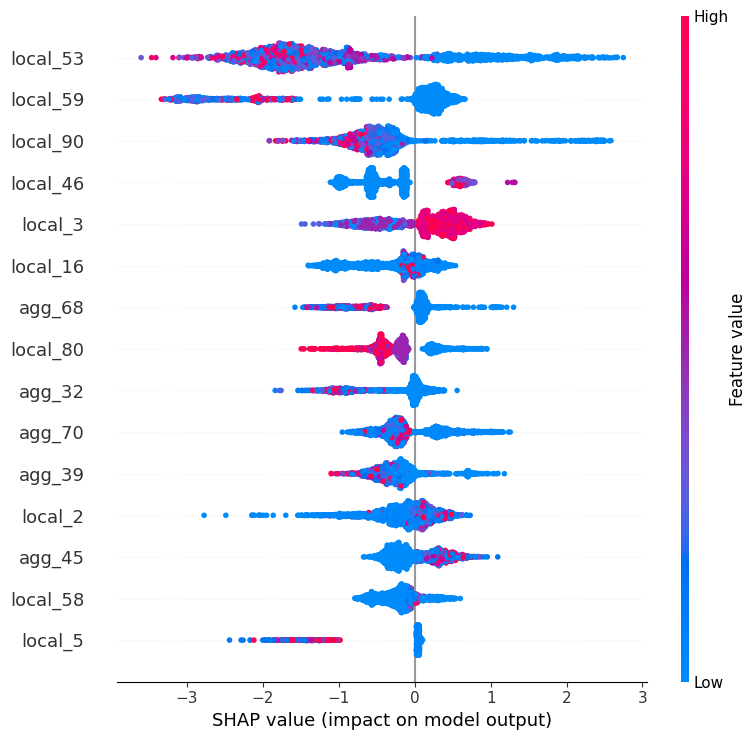

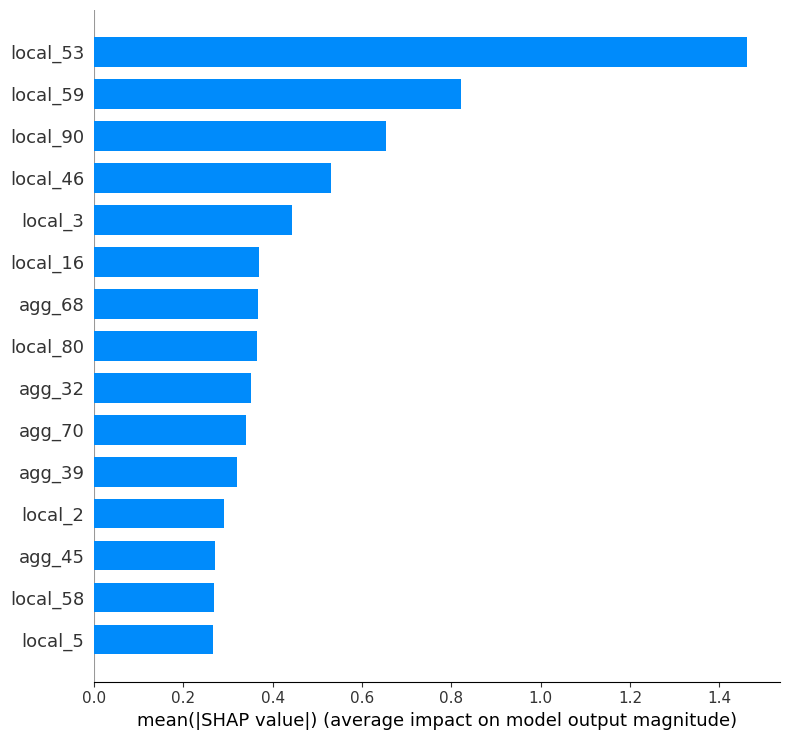

In [5]:
shap.summary_plot(sv, Xs, feature_names=names, max_display=15, show=False)
plt.savefig(path + 'shap_summary.png', dpi=200, bbox_inches='tight'); plt.show()

shap.summary_plot(sv, Xs, feature_names=names, plot_type='bar', max_display=15, show=False)
plt.savefig(path + 'shap_bar.png', dpi=200, bbox_inches='tight'); plt.show()

In [6]:
imp = np.abs(sv).mean(axis=0)
share = imp[:93].sum() / imp.sum()
print('Local features:     ', round(100 * share, 1), '%')
print('Aggregated features:', round(100 * (1 - share), 1), '%')

Local features:      65.6 %
Aggregated features: 34.4 %


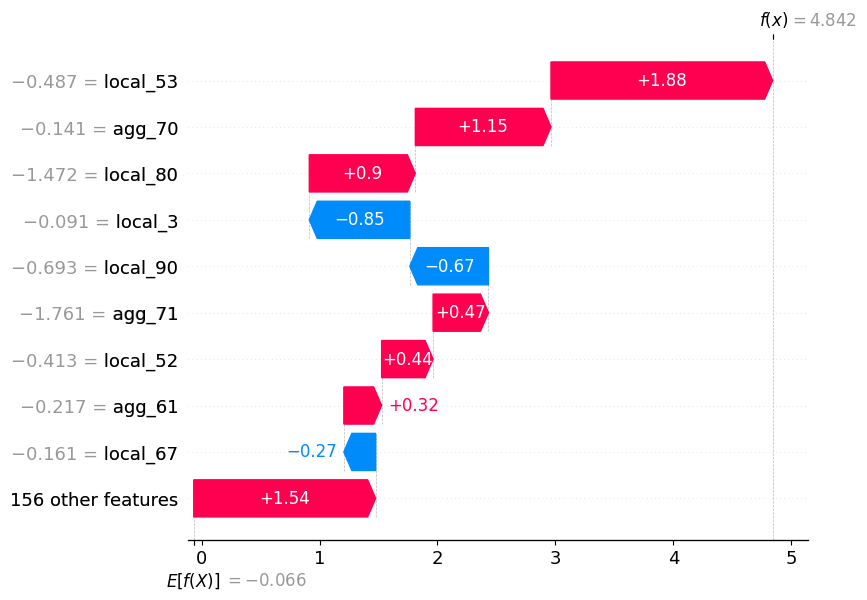

Case 1 | fraud probability: 0.992


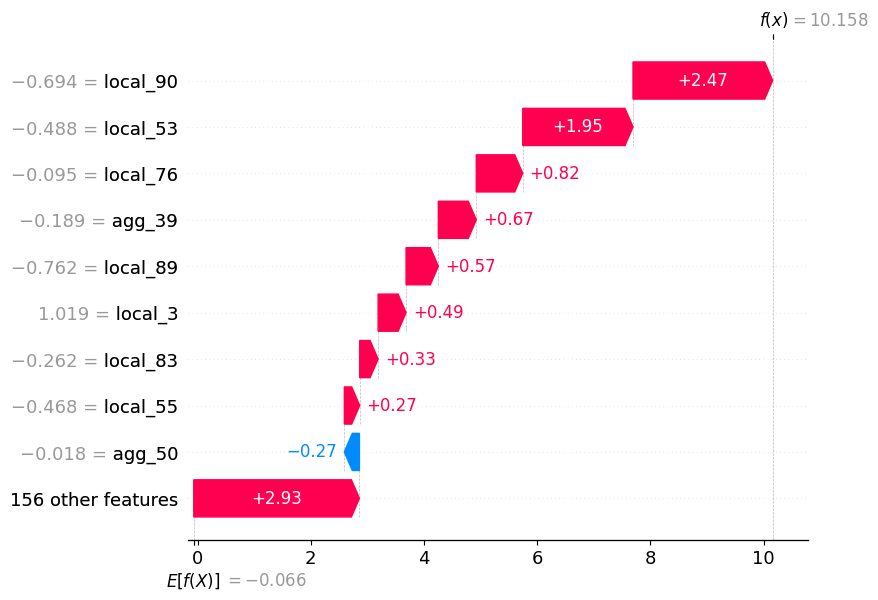

Case 2 | fraud probability: 1.0


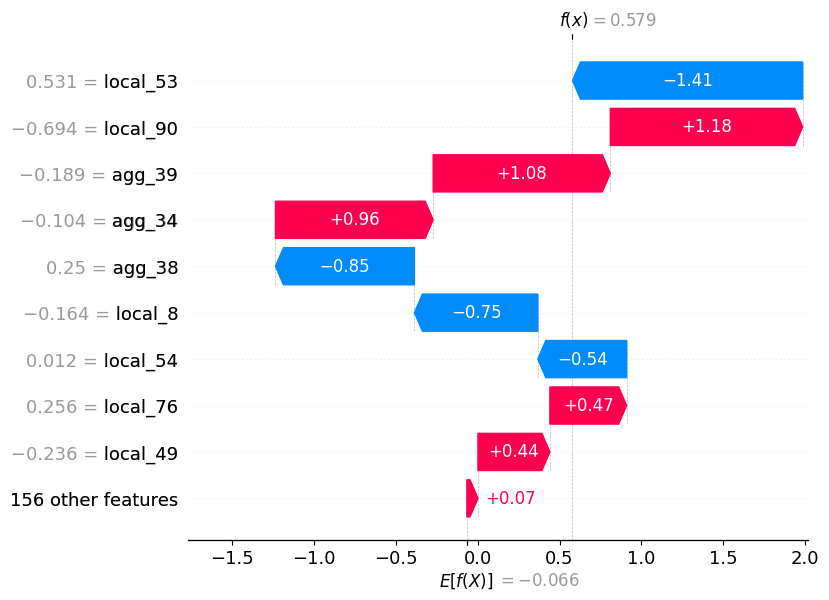

Case 3 | fraud probability: 0.641


In [7]:
flag = np.where((p > 0.5) & (yte == 1))[0][:3]
base = float(np.ravel(explainer.expected_value)[0])

for k, i in enumerate(flag, 1):
    sv_i = explainer.shap_values(Xte[i:i+1])[0]
    exp = shap.Explanation(values=sv_i, base_values=base, data=Xte[i], feature_names=names)
    shap.plots.waterfall(exp, max_display=10, show=False)
    plt.savefig(path + f'shap_case{k}.png', dpi=200, bbox_inches='tight'); plt.show()
    print('Case', k, '| fraud probability:', round(float(p[i]), 3))

In [8]:
import os
print('xgb_model.json' in os.listdir(path))

True


In [9]:
imp = np.abs(sv).mean(axis=0)
for i in imp.argsort()[::-1][:5]:
    print(names[i], round(float(imp[i]), 3))

local_53 1.463
local_59 0.821
local_90 0.654
local_46 0.531
local_3 0.444


In [10]:
from sklearn.metrics import average_precision_score

groups = {'All 165': slice(0, 165), 'Local only (93)': slice(0, 93), 'Aggregated only (72)': slice(93, 165)}
rows = []
for name, c in groups.items():
    m = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                      scale_pos_weight=ratio, random_state=42, eval_metric='logloss').fit(Xtr[:, c], ytr)
    pp = m.predict_proba(Xte[:, c])[:, 1]
    rows.append({'Features': name, 'F1': round(f1_score(yte, (pp > 0.5).astype(int)), 3),
                 'PR-AUC': round(average_precision_score(yte, pp), 3)})
ablation = pd.DataFrame(rows)
ablation.to_csv(path + 'xgb_feature_ablation.csv', index=False)
ablation

,Features,F1,PR-AUC
0,All 165,0.794,0.800
1,Local only (93),0.739,0.785
2,Aggregated only (72),0.602,0.662



Features	F1	PR-AUC
0	All 165	0.794	0.800
1	Local only (93)	0.739	0.785
2	Aggregated only (72)	0.602	0.662


In [11]:
imp = np.abs(sv).mean(axis=0)
for i in imp.argsort()[::-1][:5]:
    print(names[i], round(float(imp[i]), 3))


local_53 1.463
local_59 0.821
local_90 0.654
local_46 0.531
local_3 0.444


Summary plot: each dot is one transaction. Red means a high feature value and blue a low one. Dots to the right pushed toward fraud and dots to the left toward legit.
Bar plot: the average size of each feature's effect, which gives a simple ranking.
Waterfall: for one transaction, it starts from the average score and adds each feature's push to reach the final score. The units are log-odds, not probabilities.
Elliptic's features are anonymised, so you can only say "local_43 pushed the score up", not what it measures. Say that in your report.